# Marajó Basin outline and isolated shapefile

This notebook reads the sedimentary-basin shapefile contained in `Bacias-zip.zip`, selects only the Marajó Basin, exports it as an independent shapefile, and plots only its outline on the Brazil location map.

In [1]:
from pathlib import Path
import zipfile
import unicodedata
import shutil

import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

import geobr

In [2]:
# ============================================================
# 1) Read the basin shapefile from Bacias-zip.zip
# ============================================================
zip_path = Path("Bacias-zip.zip")
extract_dir = Path("bacias_extracted")
extract_dir.mkdir(exist_ok=True)

if not zip_path.exists():
    raise FileNotFoundError(
        f"File not found: {zip_path.resolve()}\n"
        "Place Bacias-zip.zip in the same folder in which this notebook is executed."
    )

with zipfile.ZipFile(zip_path, "r") as zf:
    zf.extractall(extract_dir)

shp_files = sorted(extract_dir.glob("*.shp"))
if not shp_files:
    raise FileNotFoundError("No .shp file was found inside Bacias-zip.zip.")

shp_path = shp_files[0]
bacias = gpd.read_file(shp_path)

# Ensure geographic coordinates
if bacias.crs is None:
    bacias = bacias.set_crs(epsg=4326)
else:
    bacias = bacias.to_crs(epsg=4326)

print(f"Shapefile loaded: {shp_path}")
print(f"Number of sedimentary basins: {len(bacias)}")
print(f"Columns: {list(bacias.columns)}")

Shapefile loaded: bacias_extracted\bacias_gishub_db.shp
Number of sedimentary basins: 72
Columns: ['feicao_id', 'situacao', 'objectid', 'name', 'code', 'creation_d', 'modificati', 'camada_id', 'geometry']


In [3]:
# ============================================================
# 2) Select only the Marajó Basin
# ============================================================
def normalize_text(value):
    value = "" if value is None else str(value)
    value = unicodedata.normalize("NFKD", value)
    value = "".join(ch for ch in value if not unicodedata.combining(ch))
    return value.strip().casefold()

if "name" not in bacias.columns:
    raise KeyError(
        f"Expected column 'name' was not found. Available columns: {list(bacias.columns)}"
    )

mask_marajo = bacias["name"].map(normalize_text).eq("marajo")
marajo_basin = bacias.loc[mask_marajo].copy()

if marajo_basin.empty:
    raise ValueError("The Marajó Basin was not found in the shapefile.")

# Merge multiple records if necessary, while preserving a single basin geometry
if len(marajo_basin) > 1:
    attrs = marajo_basin.iloc[[0]].drop(columns="geometry").copy()
    geom = marajo_basin.geometry.union_all()
    marajo_basin = gpd.GeoDataFrame(attrs, geometry=[geom], crs=bacias.crs)

print(marajo_basin.drop(columns="geometry"))
print("Marajó Basin bounds [W, S, E, N]:", marajo_basin.total_bounds)

    feicao_id   situacao  objectid    name  code creation_d modificati  \
39  3863797.0  Terrestre        49  Marajó  None 2026-08-05 2026-08-05   

    camada_id  
39         10  
Marajó Basin bounds [W, S, E, N]: [-51.2115  -5.6941 -46.832    1.1021]


In [4]:
# ============================================================
# 3) Save the Marajó Basin as an isolated shapefile
# ============================================================
output_shape_dir = Path("marajo_basin_shapefile")
output_shape_dir.mkdir(exist_ok=True)

marajo_shp_path = output_shape_dir / "marajo_basin.shp"

# Remove previous shapefile components with the same basename
for old_file in output_shape_dir.glob("marajo_basin.*"):
    if old_file.is_file():
        old_file.unlink()

marajo_basin.to_file(
    marajo_shp_path,
    driver="ESRI Shapefile",
    index=False,
    encoding="UTF-8"
)

print(f"Isolated Marajó Basin shapefile saved to: {marajo_shp_path.resolve()}")

Isolated Marajó Basin shapefile saved to: C:\Users\Usuario\Python_Notebooks\ms_ctpg\marajo_basin_shapefile\marajo_basin.shp


C:\Users\Usuario\AppData\Roaming\Python\Python311\site-packages\pyogrio\raw.py:733: RuntimeWarning: Field creation_d created as String field, though DateTime requested.
  ogr_write(
C:\Users\Usuario\AppData\Roaming\Python\Python311\site-packages\pyogrio\raw.py:733: RuntimeWarning: Field modificati created as String field, though DateTime requested.
  ogr_write(


In [5]:
# ============================================================
# 4) Load Brazil and state boundaries
# ============================================================
brasil = geobr.read_country(year=2020)
estados = geobr.read_state(year=2020)

# Use the same CRS as the Marajó Basin
brasil = brasil.to_crs(epsg=4326)
estados = estados.to_crs(epsg=4326)

possible_region_cols = ["name_region", "region", "nome_regiao", "regiao"]
possible_abbrev_cols = ["abbrev_state", "sigla_uf", "sigla_state", "abbrev"]
possible_name_cols = ["name_state", "nome_estado", "state_name", "nome"]

region_col = next((c for c in possible_region_cols if c in estados.columns), None)
abbrev_col = next((c for c in possible_abbrev_cols if c in estados.columns), None)
name_col = next((c for c in possible_name_cols if c in estados.columns), None)

pt_to_en_region = {
    "Norte": "North",
    "Nordeste": "Northeast",
    "Centro-Oeste": "Central-West",
    "Sudeste": "Southeast",
    "Sul": "South"
}

uf_to_region_en = {
    "AC": "North", "AP": "North", "AM": "North", "PA": "North",
    "RO": "North", "RR": "North", "TO": "North",
    "AL": "Northeast", "BA": "Northeast", "CE": "Northeast",
    "MA": "Northeast", "PB": "Northeast", "PE": "Northeast",
    "PI": "Northeast", "RN": "Northeast", "SE": "Northeast",
    "DF": "Central-West", "GO": "Central-West", "MT": "Central-West", "MS": "Central-West",
    "ES": "Southeast", "MG": "Southeast", "RJ": "Southeast", "SP": "Southeast",
    "PR": "South", "RS": "South", "SC": "South"
}

state_to_region_en = {
    "Acre": "North", "Amapá": "North", "Amazonas": "North", "Pará": "North",
    "Rondônia": "North", "Roraima": "North", "Tocantins": "North",
    "Alagoas": "Northeast", "Bahia": "Northeast", "Ceará": "Northeast",
    "Maranhão": "Northeast", "Paraíba": "Northeast", "Pernambuco": "Northeast",
    "Piauí": "Northeast", "Rio Grande do Norte": "Northeast", "Sergipe": "Northeast",
    "Distrito Federal": "Central-West", "Goiás": "Central-West",
    "Mato Grosso": "Central-West", "Mato Grosso do Sul": "Central-West",
    "Espírito Santo": "Southeast", "Minas Gerais": "Southeast",
    "Rio de Janeiro": "Southeast", "São Paulo": "Southeast",
    "Paraná": "South", "Rio Grande do Sul": "South", "Santa Catarina": "South"
}

if region_col is not None:
    estados["region_en"] = estados[region_col].replace(pt_to_en_region)
elif abbrev_col is not None:
    estados["region_en"] = estados[abbrev_col].map(uf_to_region_en)
elif name_col is not None:
    estados["region_en"] = estados[name_col].map(state_to_region_en)
else:
    raise ValueError(
        f"Could not identify a region/state column. Available columns: {list(estados.columns)}"
    )

region_colors = {
    "North": "#b6d2a8",
    "Northeast": "#f5e7c7",
    "Central-West": "#e8f2cf",
    "Southeast": "#f2ddd2",
    "South": "#dfe9df"
}

estados["color"] = estados["region_en"].map(region_colors).fillna("#dddddd")

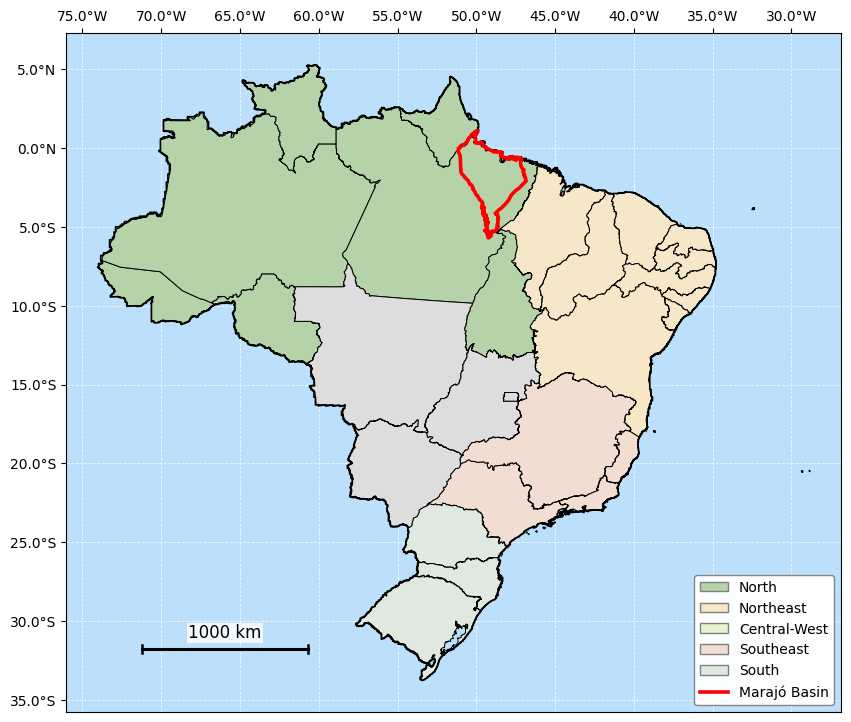

In [6]:
# ============================================================
# 5) Brazil location map with ONLY the Marajó Basin outline
# ============================================================
fig, ax = plt.subplots(figsize=(10, 10))
ax.set_facecolor("#bcdffb")
fig.patch.set_facecolor("white")

# States colored by geographic region
estados.plot(
    ax=ax,
    color=estados["color"],
    edgecolor="black",
    linewidth=0.7,
    zorder=2
)

# External border of Brazil
brasil.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.2,
    zorder=3
)

# ONLY the Marajó Basin sedimentary-basin boundary
marajo_basin.boundary.plot(
    ax=ax,
    color="red",
    linewidth=2.6,
    zorder=6
)

# Brazil limits
minx, miny, maxx, maxy = brasil.total_bounds
ax.set_xlim(minx - 2, maxx + 2)
ax.set_ylim(miny - 2, maxy + 2)

# Geographic ticks
x_ticks = np.arange(-75, -30 + 1, 5)
y_ticks = np.arange(-35, 5 + 1, 5)
ax.set_xticks(x_ticks)
ax.set_yticks(y_ticks)

def lon_formatter(x, pos):
    return f"{abs(x):.1f}°W" if x < 0 else f"{x:.1f}°E"

def lat_formatter(y, pos):
    return f"{abs(y):.1f}°S" if y < 0 else f"{y:.1f}°N"

ax.xaxis.set_major_formatter(FuncFormatter(lon_formatter))
ax.yaxis.set_major_formatter(FuncFormatter(lat_formatter))

ax.tick_params(
    axis="x",
    top=True,
    labeltop=True,
    bottom=False,
    labelbottom=False,
    direction="out"
)
ax.tick_params(
    axis="y",
    left=True,
    labelleft=True,
    right=False,
    labelright=False,
    direction="out"
)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    color="white",
    alpha=0.85,
    zorder=1
)

# Scale bar: 1000 km
bar_lon = minx + 2.8
bar_lat = miny + 2.0
distance_km = 1000
km_per_degree_lon = 111.32 * np.cos(np.radians(bar_lat))
delta_lon = distance_km / km_per_degree_lon
end_lon = bar_lon + delta_lon

ax.plot([bar_lon, end_lon], [bar_lat, bar_lat], color="black", linewidth=2.2, zorder=9)
tick_h = 0.25
ax.plot([bar_lon, bar_lon], [bar_lat - tick_h, bar_lat + tick_h], color="black", linewidth=1.8, zorder=9)
ax.plot([end_lon, end_lon], [bar_lat - tick_h, bar_lat + tick_h], color="black", linewidth=1.8, zorder=9)

ax.text(
    (bar_lon + end_lon) / 2,
    bar_lat + 0.45,
    "1000 km",
    ha="center",
    va="bottom",
    fontsize=12,
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1),
    zorder=10
)

# Legend
legend_handles = [
    Patch(facecolor=region_colors["North"], edgecolor="gray", label="North"),
    Patch(facecolor=region_colors["Northeast"], edgecolor="gray", label="Northeast"),
    Patch(facecolor=region_colors["Central-West"], edgecolor="gray", label="Central-West"),
    Patch(facecolor=region_colors["Southeast"], edgecolor="gray", label="Southeast"),
    Patch(facecolor=region_colors["South"], edgecolor="gray", label="South"),
    Line2D([0], [0], color="red", linewidth=2.6, label="Marajó Basin")
]

ax.legend(
    handles=legend_handles,
    loc="lower right",
    frameon=True,
    framealpha=0.95,
    facecolor="white",
    edgecolor="gray",
    fontsize=10
)

ax.set_xlabel("")
ax.set_ylabel("")

# Optional title
# ax.set_title("Location of the Marajó Basin, northern Brazil", fontsize=13)

#plt.savefig("location_marajo_basin_brazil.png", dpi=300, bbox_inches="tight")
plt.show()